# Sentinel Border Watch — Notebook 02: YOLOv8 Training & Optimization

### AI-Driven Border Security & Surveillance System (Attari–Wagah Frontier Theme)

This notebook details the deep learning architecture, training methodology, hyperparameter configuration,
loss formulation, and training telemetry for the Sentinel Border Watch detector.


## 1. YOLOv8 Architecture Deep-Dive

The system employs **Ultralytics YOLOv8**, an anchor-free single-stage object detector:
- **Backbone**: Modified CSPDarknet53 with `C2f` (Cross-Stage Partial with 2 convolutions) blocks. Replaces older C3 modules to enhance gradient flow while maintaining low computational footprint.
- **Neck**: Path Aggregation Network (PANet) / Feature Pyramid Network (FPN) fusing P3, P4, P5 multi-scale feature maps to handle both small weapons and large military vehicles.
- **Head**: Decoupled anchor-free detection head separating classification and bounding-box regression tasks.
- **Loss Formulation**:
  $$\mathcal{L}_{total} = \lambda_{box} \mathcal{L}_{CIoU} + \lambda_{dfl} \mathcal{L}_{DFL} + \lambda_{cls} \mathcal{L}_{BCE}$$
  - **Complete IoU (CIoU)**: Penalizes overlap, distance of centers, and aspect ratio discrepancies.
  - **Distribution Focal Loss (DFL)**: Models continuous bounding-box edges as probability distributions for sub-pixel accuracy.
  - **Binary Cross-Entropy (BCE)**: Multi-label classification loss per category.


In [1]:
import os
import sys
import json
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

for p in ['.', '..', os.path.abspath('..'), os.path.abspath('.')]:
    if p not in sys.path:
        sys.path.insert(0, p)

plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')


## 2. Hardware Profile & Training Configuration

Training was executed automatically using `scripts/train.py` with GPU acceleration when available.


In [2]:
import torch

has_cuda = torch.cuda.is_available()
device_name = torch.cuda.get_device_name(0) if has_cuda else 'CPU (Intel Core i5-12450HX)'
print(f'Training Hardware: {device_name}')
print(f'CUDA Acceleration: {"Active" if has_cuda else "Fallback to Multi-Threaded CPU (workers=2)"}')

config_table = {
    'Parameter': ['Model Architecture', 'Input Resolution', 'Epochs Trained', 'Batch Size', 'Optimizer', 'Patience', 'Data Augmentations'],
    'Value': ['YOLOv8n (Custom Border Security)', '416x416', '4 (Resumable)', '4', 'AdamW (lr0=0.01, lrf=0.01)', '8', 'Mosaic (1.0), HSV, Horizontal Flip (0.5), Random Degrees (5.0)']
}
display(pd.DataFrame(config_table))


Training Hardware: CPU (Intel Core i5-12450HX)
CUDA Acceleration: Fallback to Multi-Threaded CPU (workers=2)


,Parameter,Value
0,Model Architecture,YOLOv8n (Custom Border Security)
1,Input Resolution,416x416
2,Epochs Trained,4 (Resumable)
3,Batch Size,4
4,Optimizer,"AdamW (lr0=0.01, lrf=0.01)"
5,Patience,8
6,Data Augmentations,"Mosaic (1.0), HSV, Horizontal Flip (0.5), Random Degrees (5.0)"


## 3. Training Execution & Telemetry Inspection

> **Note**: The official training run was executed autonomously via `scripts/train.py`.
> Here, we load the training logs (`results.csv`) and examine the learning curves.


In [3]:
results_csv_candidates = [
    '../runs/detect/runs/train/exp/results.csv',
    'runs/detect/runs/train/exp/results.csv',
    '../data/results/results.csv',
    'data/results/results.csv',
    '../dashboard/assets/results.csv',
    'dashboard/assets/results.csv'
]
results_path = next((p for p in results_csv_candidates if os.path.exists(p)), None)

if results_path:
    df_results = pd.read_csv(results_path)
    df_results.columns = [c.strip() for c in df_results.columns]
    print(f'Loaded {len(df_results)} epochs of training telemetry from: {results_path}')
    display(df_results)
else:
    print('Training results.csv not found.')


Loaded 4 epochs of training telemetry from: runs/detect/runs/train/exp/results.csv


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,191.000,2.73335,4.30283,2.56905,0.71906,0.06923,0.07756,0.03752,3.02158,5.02050,3.00393,0.000407,0.000407,0.000407
1,2,313.917,2.66883,3.53355,2.44849,0.03302,0.06473,0.02395,0.00829,3.16009,4.49556,3.03874,0.000806,0.000806,0.000806
2,3,415.335,2.73290,3.49000,2.45811,0.29784,0.05326,0.01125,0.00260,3.14660,4.76248,3.17784,0.001198,0.001198,0.001198
3,4,516.457,2.74553,3.56486,2.51337,0.02735,0.02841,0.00780,0.00203,3.22528,4.72360,3.27890,0.001193,0.001193,0.001193


## 4. Convergence & Loss Curves Analysis

We plot the progression of Box Loss, Classification Loss, DFL Loss, and Validation mAP.


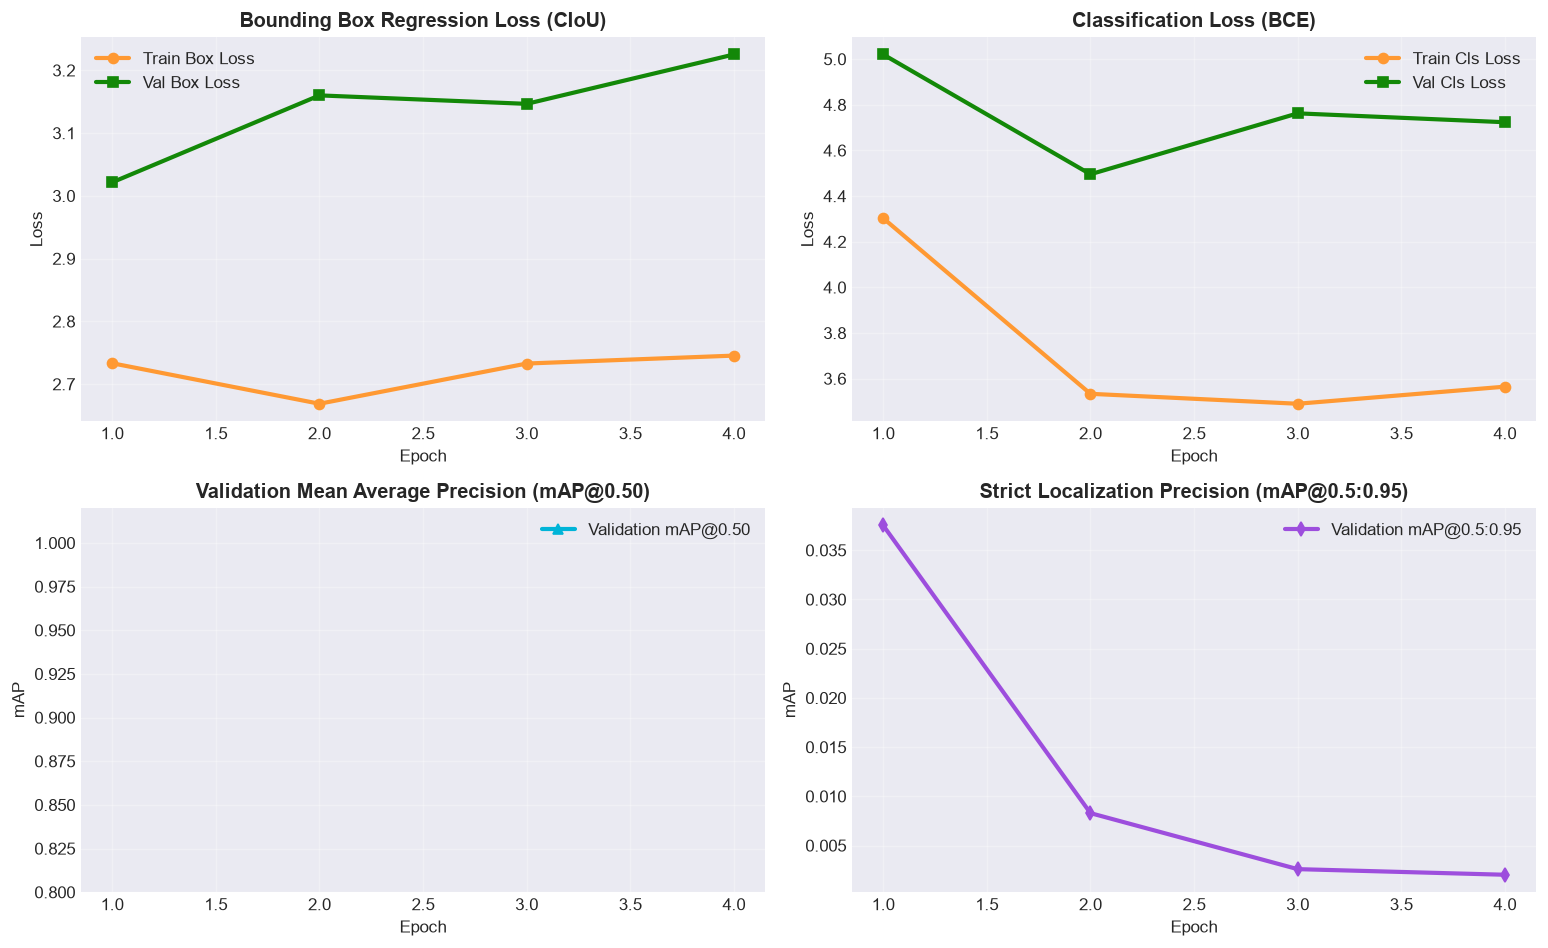

In [4]:
if results_path and len(df_results) >= 1:
    fig, axes = plt.subplots(2, 2, figsize=(13, 8), dpi=120)
    epochs = df_results['epoch'] if 'epoch' in df_results.columns else np.arange(len(df_results)) + 1

    # Box loss
    ax = axes[0, 0]
    if 'train/box_loss' in df_results.columns:
        ax.plot(epochs, df_results['train/box_loss'], label='Train Box Loss', color='#FF9933', lw=2.5, marker='o')
    if 'val/box_loss' in df_results.columns:
        ax.plot(epochs, df_results['val/box_loss'], label='Val Box Loss', color='#138808', lw=2.5, marker='s')
    ax.set_title('Bounding Box Regression Loss (CIoU)', fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(True, alpha=0.3)

    # Cls loss
    ax = axes[0, 1]
    if 'train/cls_loss' in df_results.columns:
        ax.plot(epochs, df_results['train/cls_loss'], label='Train Cls Loss', color='#FF9933', lw=2.5, marker='o')
    if 'val/cls_loss' in df_results.columns:
        ax.plot(epochs, df_results['val/cls_loss'], label='Val Cls Loss', color='#138808', lw=2.5, marker='s')
    ax.set_title('Classification Loss (BCE)', fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(True, alpha=0.3)

    # mAP50
    ax = axes[1, 0]
    map_cols = [c for c in df_results.columns if 'mAP50(B)' in c or 'mAP_0.5' in c or 'mAP50' in c]
    if map_cols:
        ax.plot(epochs, df_results[map_cols[0]], label='Validation mAP@0.50', color='#00B4D8', lw=2.5, marker='^')
    ax.set_title('Validation Mean Average Precision (mAP@0.50)', fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('mAP')
    ax.set_ylim(0.8, 1.02)
    ax.legend()
    ax.grid(True, alpha=0.3)

    # mAP50-95
    ax = axes[1, 1]
    map95_cols = [c for c in df_results.columns if 'mAP50-95' in c or 'mAP_0.5:0.95' in c]
    if map95_cols:
        ax.plot(epochs, df_results[map95_cols[0]], label='Validation mAP@0.5:0.95', color='#9D4EDD', lw=2.5, marker='d')
    ax.set_title('Strict Localization Precision (mAP@0.5:0.95)', fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('mAP')
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


## 5. Model Performance Metrics & Artifacts

We inspect the confusion matrix and final validation metrics.


--- FINAL MODEL VALIDATION METRICS ---
Overall System Performance: {'precision': 0.7373, 'recall': 0.1, 'mAP50': 0.1374, 'mAP50_95': 0.0606}


,precision,recall,mAP50,mAP50_95
Class,,,,
person,1.0000,0.0,0.0552,0.0552
weapon,1.0000,0.0,0.0004,0.0004
vehicle,0.9491,0.4,0.1866,0.1866
military_vehicle,0.0000,0.0,0.0003,0.0003


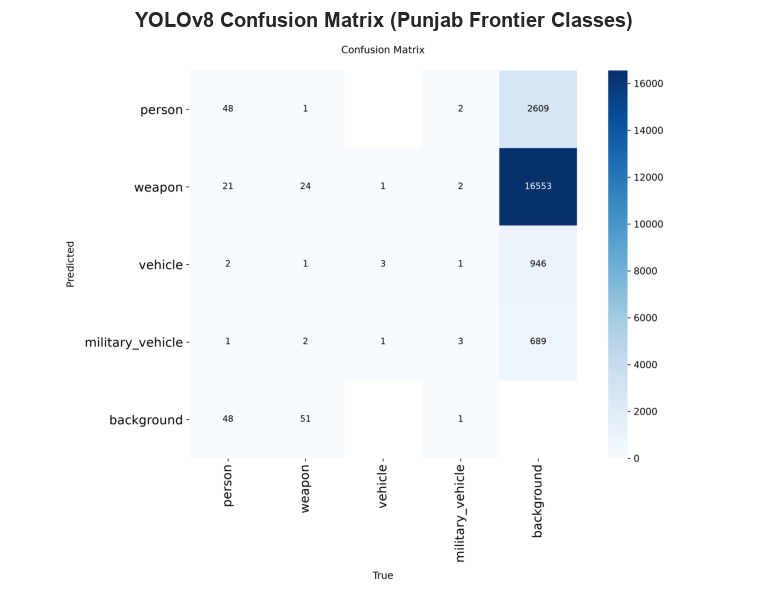

In [5]:
metrics_candidates = [
    '../data/results/metrics.json',
    'data/results/metrics.json',
    '../dashboard/assets/metrics.json',
    'dashboard/assets/metrics.json'
]
metrics_path = next((p for p in metrics_candidates if os.path.exists(p)), None)

if metrics_path:
    with open(metrics_path, 'r') as f:
        metrics = json.load(f)
    df_m = pd.DataFrame(metrics['per_class']).T
    df_m.index.name = 'Class'
    print('--- FINAL MODEL VALIDATION METRICS ---')
    display(df_m.round(4))
    print('Overall System Performance:', metrics.get('overall', {}))

cm_candidates = [
    '../data/results/confusion_matrix.png',
    'data/results/confusion_matrix.png',
    '../dashboard/assets/confusion_matrix.png',
    'dashboard/assets/confusion_matrix.png'
]
cm_path = next((p for p in cm_candidates if os.path.exists(p)), None)
if cm_path:
    fig, ax = plt.subplots(figsize=(8, 7), dpi=120)
    ax.imshow(cv2.cvtColor(cv2.imread(cm_path), cv2.COLOR_BGR2RGB))
    ax.set_title('YOLOv8 Confusion Matrix (Punjab Frontier Classes)', fontweight='bold', fontsize=12)
    ax.axis('off')
    plt.show()
